# Lab 1.9 · Few-step image generation

**15–20 minutes · CPU**

Read the [lab guide](README.md), then run the setup. Replace each `return None` with your implementation and rerun its check.

## Concepts and worked example

What is the cost of using fewer denoising steps, and why might a model be trained specifically for that regime?

A solver advances the sample along a path described by model predictions. With a simple Euler update, each call estimates the local direction and holds it fixed for one interval. Bigger intervals mean fewer calls. When the direction varies with the sample, a large interval can introduce more error. Few-step models can be trained to make useful progress over larger intervals, for example by learning from the endpoints of a slower teacher trajectory.

This lab uses the scalar equation dx/dt = −x. Its exact evolution over an interval h multiplies the value by exp(−h). Starting at 1, one Euler step of size 0.5 gives 0.5, while the exact value at that time is about 0.607. We provide the exact interval update as an idealized stand-in for a learned jump. The endpoint error measures this equation only. The model-call count is a work proxy. In a real pipeline, a scheduler step can use more than one denoiser evaluation, for example when guidance evaluates two conditioning branches.

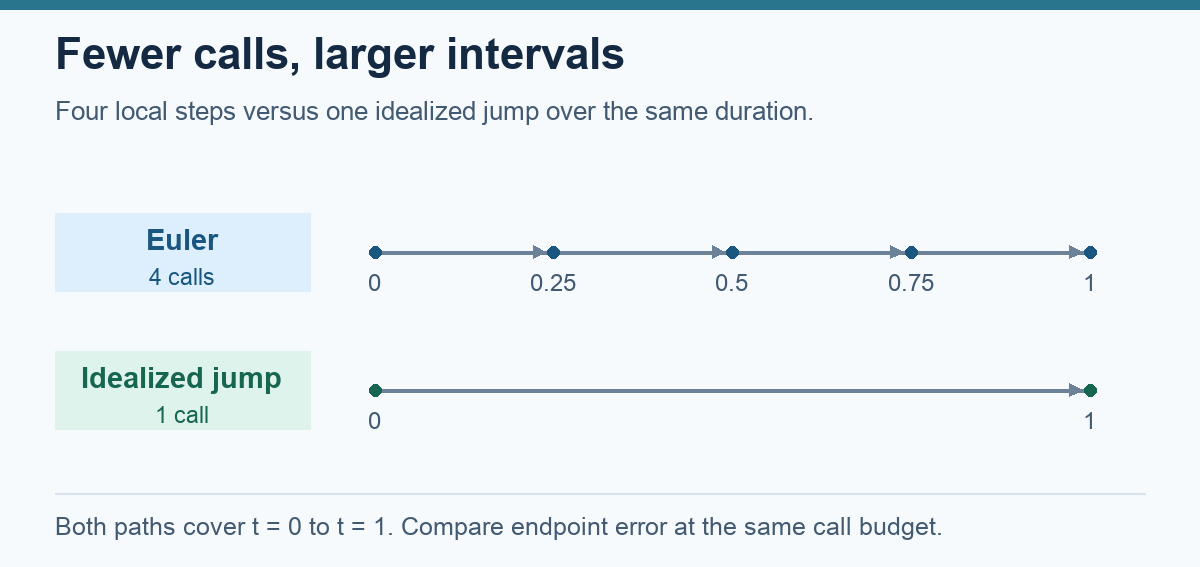

## Exercise map

| Exercise | What you will do | What to inspect |
| --- | --- | --- |
| 1. Compare step budgets | Integrate to the same end time with different Euler budgets. | Record endpoint error and calls. |
| 2. Compare update rules | Swap in the supplied interval update at the same budgets. | Separate the effect of the step count from the effect of the update rule. |

In [ ]:
from math import exp, isclose

start, duration = 1.0, 1.0
target = start * exp(-duration)
budgets = (1, 2, 4, 16)

def local_euler(x, h):
    return x - h * x

def idealized_jump(x, h):
    return x * exp(-h)

print("Reference endpoint:", round(target, 6))

## Exercise 1. Advance with a fixed budget

Split the total duration into equal intervals. Call step once per interval, carrying its output forward. Return the endpoint and the number of calls. Predict which Euler budget has the highest endpoint error.

In [ ]:
def simulate(start, duration, steps, step):
    return None

In [ ]:
probe = simulate(start, duration, 2, local_euler)
if probe is not None:
    assert probe == (0.25, 2)
    rows = [simulate(start, duration, n, local_euler) for n in budgets]
    errors = [abs(value - target) for value, _ in rows]
    assert [count for _, count in rows] == list(budgets)
    assert all(a > b for a, b in zip(errors, errors[1:]))
    for n, err in zip(budgets, errors):
        print(n, "calls; Euler endpoint error:", round(err, 6))
    print("PASS — more local evaluations reduce error in this setup")

### Read the result

Keep total integration time fixed. Increase the number of updates and inspect the endpoint error.

## Exercise 2. Compare two update rules at equal budgets

For every budget, call simulate with both methods at the same start and duration. Return tuples of (calls, Euler error, jump error). Then compare the first row with the last. The supplied exact interval formula illustrates the target of a better large jump.

In [ ]:
def compare(budgets):
    return None

In [ ]:
check_passed = False
if probe is not None:
    comparison = compare(budgets)
    if comparison is not None:
        assert [row[0] for row in comparison] == list(budgets)
        assert isclose(comparison[0][1], target)
        assert all(jump_error < 1e-12 for _, _, jump_error in comparison)
        print("Calls   Euler error   Idealized jump error")
        for calls, euler_error, jump_error in comparison:
            print(f"{calls:>5}   {euler_error:>11.6f}   {jump_error:>20.6f}")
        print("PASS — the interval rule changes accuracy at the same call budget")
        check_passed = True
if not check_passed:
    print("Complete simulate and compare and rerun the checks in order.")

### Read the result

Compare methods within the same budget row. The exact scalar update illustrates a target for larger jumps, with no image-quality claim.

## Compare your results

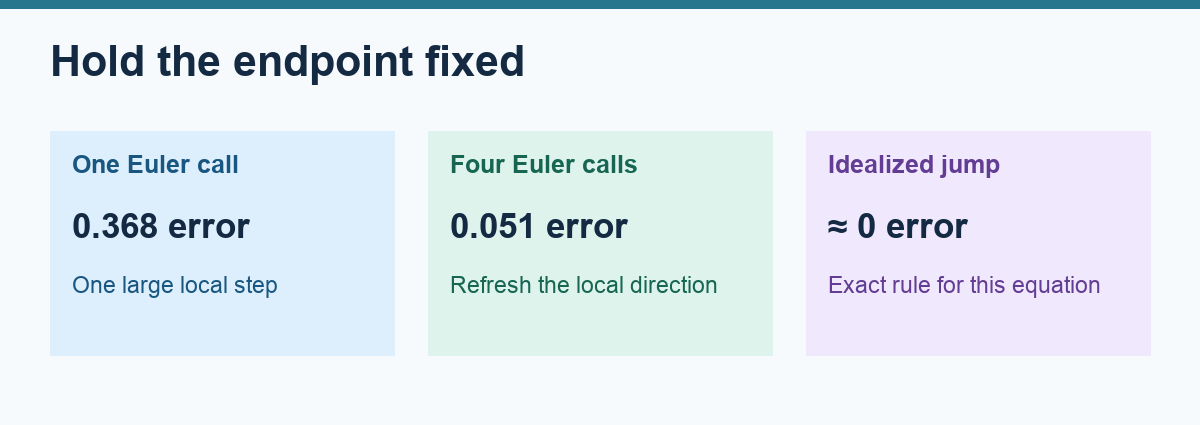

## Optional extension · What the training changes

Kiely discusses two ways to design a generator for a small number of evaluations. **Latent consistency** trains predictions made at different points along a denoising trajectory to agree on the destination. A few evaluations can progressively improve the result. **Distillation** trains a student using a teacher, for example by learning an update that covers multiple smaller teacher steps. Choosing a smaller step budget for an unchanged model leaves its learned predictions unchanged.

The exact jump in this notebook stands in for an ideal prediction. It is computed analytically. The extension constructs a fixed two-step teacher target to show what a student could learn from, then compares that target with a single large Euler step.

From input 1.0, compare two teacher steps of size 0.25 with one Euler step of size 0.5. Both reach the same time. Repeat from 0.8. If a student could reproduce each teacher endpoint in one evaluation, what would be saved? How would you check whether the student preserved quality on unseen prompts?

Predict the result before you run the cell.

**Reading** · Philip Kiely, *Inference Engineering*, §2.3.2, p. 59.

In [ ]:
for x in (1.0, 0.8):
    teacher = local_euler(local_euler(x, 0.25), 0.25)
    one_large_step = local_euler(x, 0.5)
    assert isclose(teacher, x * 0.5625)
    print(f"Input {x}: teacher target {teacher:.4f}, large Euler step {one_large_step:.4f}")

## Wrap-up

Would a model with fewer calls always have lower latency if each of its calls costs more? What would you hold fixed and measure when comparing two real image generators?

## Optional system exercise · Comparing quality at matched budgets

Design a comparison of a few-step student with its teacher on held-out prompts. State what stays fixed, which latency statistic you would report across prompts, and what would make the student unacceptable even if it is faster.